In [1]:
# Cell 1: Install XGBoost if needed, then import libraries
%pip -q install xgboost

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    classification_report, confusion_matrix, RocCurveDisplay
)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
os.makedirs("outputs", exist_ok=True)
print("XGBoost version:", xgb.__version__)

XGBoost version: 3.4.1


In [2]:
# Cell 2: Load telecom churn data
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(url)
print("Shape:", df.shape)
display(df.head())
print("Columns:", df.columns.tolist())

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Columns: ['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [3]:
# Cell 3: Clean target and TotalCharges
target = "Churn"
if target not in df.columns:
    raise ValueError("The expected Churn target column was not found.")

# TotalCharges may contain empty strings; coerce invalid values to NaN.
if "TotalCharges" in df.columns:
    df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

df = df.dropna(subset=[target]).copy()
df[target] = df[target].map({"No": 0, "Yes": 1})
df = df.dropna(subset=[target])
df[target] = df[target].astype(int)

# customerID is an identifier, not a useful predictive feature.
if "customerID" in df.columns:
    df = df.drop(columns=["customerID"])

print("Cleaned shape:", df.shape)
print("Churn distribution:")
display(df[target].value_counts().rename(index={0:"No churn", 1:"Churn"}).to_frame("count"))
display(df.isna().sum().sort_values(ascending=False).head(10).to_frame("missing_count"))

Cleaned shape: (7043, 20)
Churn distribution:


,count
Churn,
No churn,5174
Churn,1869


,missing_count
TotalCharges,11
gender,0
Partner,0
SeniorCitizen,0
Dependents,0
tenure,0
MultipleLines,0
PhoneService,0
OnlineSecurity,0
OnlineBackup,0


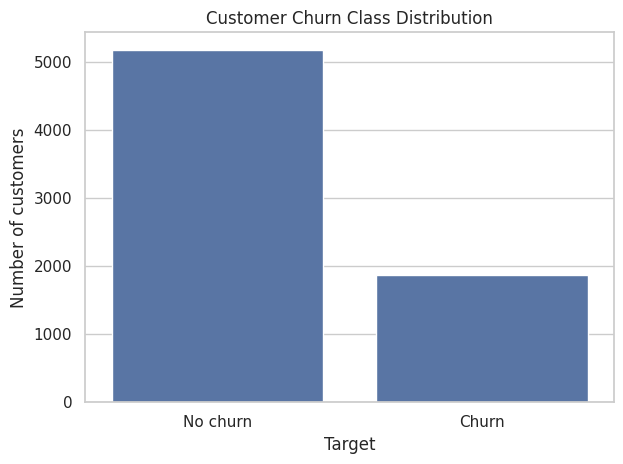

In [4]:
# Cell 4: Visualize class distribution
ax = sns.countplot(data=df, x=target)
ax.set_xticks([0, 1], labels=["No churn", "Churn"])
ax.set_title("Customer Churn Class Distribution")
ax.set_xlabel("Target")
ax.set_ylabel("Number of customers")
plt.tight_layout()
plt.savefig("outputs/task3_class_distribution.png", dpi=160, bbox_inches="tight")
plt.show()

In [5]:
# Cell 5: Train/test split and identify feature types
X = df.drop(columns=[target])
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=np.number).columns.tolist()
print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)
print("Training rows:", len(X_train), "| Test rows:", len(X_test))
print("Training churn rate:", round(y_train.mean(), 4))

Numeric features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Training rows: 5634 | Test rows: 1409
Training churn rate: 0.2654


In [6]:
# Cell 6: Preprocessing
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

# Transform only after splitting; fit is performed on training data.
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)
print("Processed train matrix:", X_train_processed.shape)
print("Processed test matrix:", X_test_processed.shape)

Processed train matrix: (5634, 45)
Processed test matrix: (1409, 45)


In [7]:
# Cell 7: Train Random Forest and XGBoost
positive = int((y_train == 1).sum())
negative = int((y_train == 0).sum())
scale_pos_weight = negative / max(positive, 1)

rf_model = RandomForestClassifier(
    n_estimators=350, max_depth=None, min_samples_leaf=2,
    class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1
)
xgb_model = xgb.XGBClassifier(
    n_estimators=350, max_depth=4, learning_rate=0.05,
    subsample=0.9, colsample_bytree=0.9,
    objective="binary:logistic", eval_metric="logloss",
    scale_pos_weight=scale_pos_weight,
    random_state=RANDOM_STATE, n_jobs=2, tree_method="hist"
)

rf_model.fit(X_train_processed, y_train)
xgb_model.fit(X_train_processed, y_train)
models = {"Random Forest": rf_model, "XGBoost": xgb_model}
print("Both models trained.")

Both models trained.


In [8]:
# Cell 8: Evaluate held-out test performance
rows = []
probabilities = {}
predictions = {}

for name, model in models.items():
    pred = model.predict(X_test_processed)
    prob = model.predict_proba(X_test_processed)[:, 1]
    predictions[name] = pred
    probabilities[name] = prob
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, prob)
    })
    print("\\n" + "="*60)
    print(name)
    print(classification_report(y_test, pred, target_names=["No churn", "Churn"], zero_division=0))

metrics_df = pd.DataFrame(rows).sort_values("ROC-AUC", ascending=False)
display(metrics_df.round(4))
metrics_df.to_csv("outputs/task3_churn_metrics.csv", index=False)

\n============================================================
Random Forest
              precision    recall  f1-score   support

    No churn       0.87      0.83      0.85      1035
       Churn       0.58      0.64      0.61       374

    accuracy                           0.78      1409
   macro avg       0.72      0.74      0.73      1409
weighted avg       0.79      0.78      0.78      1409

\n============================================================
XGBoost
              precision    recall  f1-score   support

    No churn       0.90      0.74      0.82      1035
       Churn       0.52      0.78      0.62       374

    accuracy                           0.75      1409
   macro avg       0.71      0.76      0.72      1409
weighted avg       0.80      0.75      0.76      1409



,Model,Accuracy,Precision,Recall,F1,ROC-AUC
1,XGBoost,0.7523,0.5225,0.7754,0.6243,0.8399
0,Random Forest,0.7793,0.5752,0.6444,0.6078,0.8344


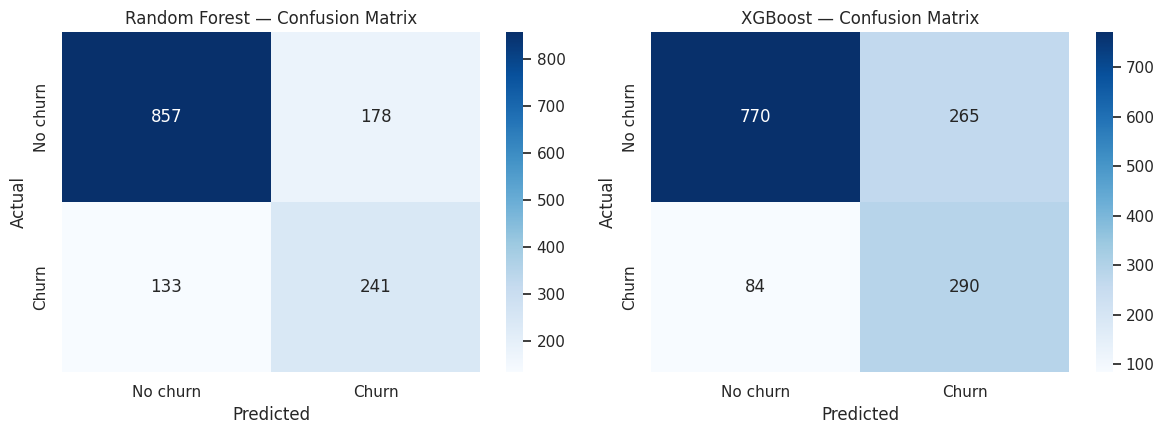

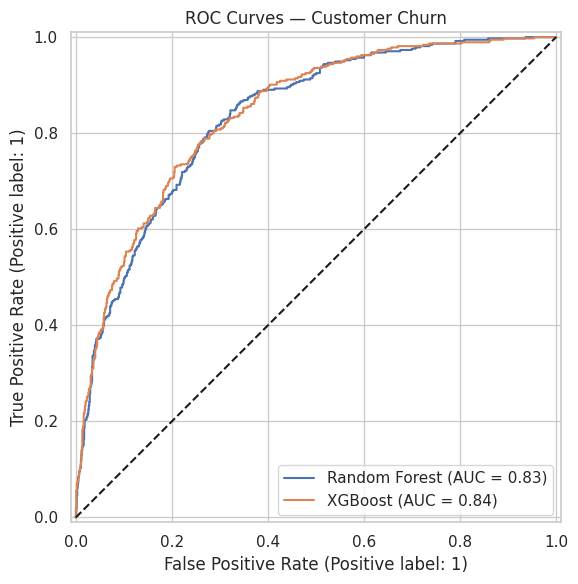

In [9]:
# Cell 9: Confusion matrices and ROC curves
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (name, pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, pred, labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=["No churn", "Churn"],
                yticklabels=["No churn", "Churn"], ax=ax)
    ax.set_title(f"{name} — Confusion Matrix")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.savefig("outputs/task3_confusion_matrices.png", dpi=160, bbox_inches="tight")
plt.show()

plt.figure(figsize=(7, 6))
for name, prob in probabilities.items():
    RocCurveDisplay.from_predictions(y_test, prob, name=name, ax=plt.gca())
plt.plot([0, 1], [0, 1], "k--", label="Random baseline")
plt.title("ROC Curves — Customer Churn")
plt.tight_layout()
plt.savefig("outputs/task3_roc_curves.png", dpi=160, bbox_inches="tight")
plt.show()

In [10]:
# Cell 10: 3-fold cross-validation ROC-AUC on training data
# Each fold fits its own preprocessing within the pipeline to avoid leakage.
cv_preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])
cv_models = {
    "Random Forest": Pipeline([
        ("preprocess", cv_preprocessor),
        ("model", RandomForestClassifier(
            n_estimators=200, min_samples_leaf=2, class_weight="balanced",
            random_state=RANDOM_STATE, n_jobs=-1
        ))
    ]),
    "XGBoost": Pipeline([
        ("preprocess", cv_preprocessor),
        ("model", xgb.XGBClassifier(
            n_estimators=250, max_depth=4, learning_rate=0.05,
            subsample=0.9, colsample_bytree=0.9,
            objective="binary:logistic", eval_metric="logloss",
            scale_pos_weight=scale_pos_weight,
            random_state=RANDOM_STATE, n_jobs=2, tree_method="hist"
        ))
    ])
}
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []
for name, model in cv_models.items():
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=1)
    cv_rows.append({"Model": name, "CV ROC-AUC mean": scores.mean(), "CV ROC-AUC std": scores.std()})
cv_df = pd.DataFrame(cv_rows)
display(cv_df.round(4))
cv_df.to_csv("outputs/task3_cross_validation.csv", index=False)

,Model,CV ROC-AUC mean,CV ROC-AUC std
0,Random Forest,0.8353,0.0071
1,XGBoost,0.8444,0.0094


\nTop features — Random Forest


,Feature,Importance
1,numeric__tenure,0.128723
3,numeric__TotalCharges,0.125676
2,numeric__MonthlyCharges,0.099785
36,categorical__Contract_Month-to-month,0.091856
18,categorical__OnlineSecurity_No,0.047465
38,categorical__Contract_Two year,0.046093
27,categorical__TechSupport_No,0.038937
16,categorical__InternetService_Fiber optic,0.037611
43,categorical__PaymentMethod_Electronic check,0.030396
21,categorical__OnlineBackup_No,0.018038


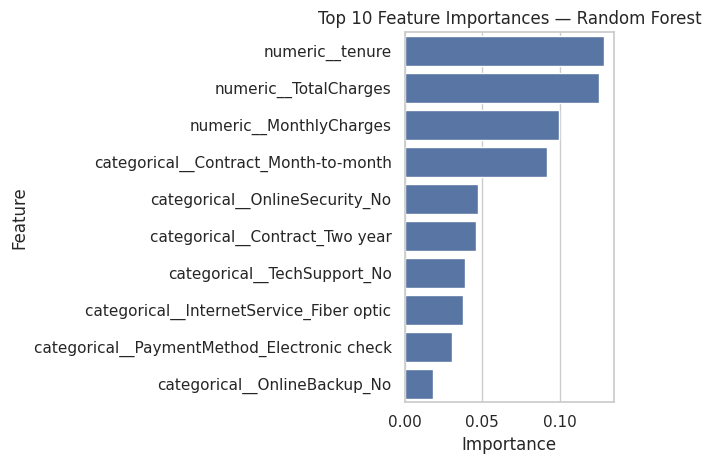

\nTop features — XGBoost


,Feature,Importance
36,categorical__Contract_Month-to-month,0.379767
16,categorical__InternetService_Fiber optic,0.104869
18,categorical__OnlineSecurity_No,0.086259
15,categorical__InternetService_DSL,0.036158
38,categorical__Contract_Two year,0.032727
27,categorical__TechSupport_No,0.028905
35,categorical__StreamingMovies_Yes,0.028732
37,categorical__Contract_One year,0.024934
43,categorical__PaymentMethod_Electronic check,0.019830
1,numeric__tenure,0.016059


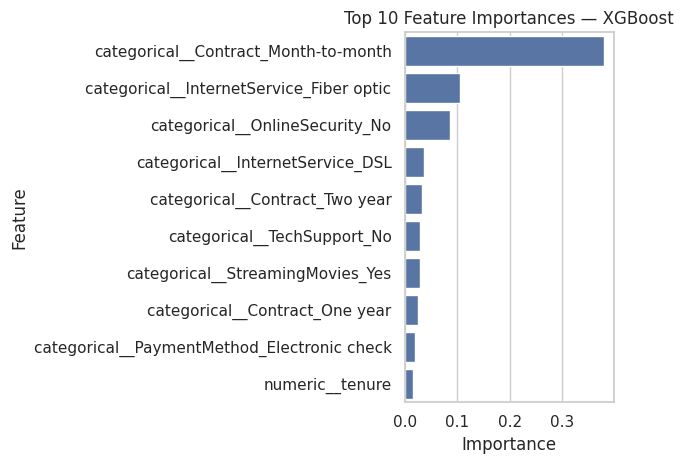

In [11]:
# Cell 11: Top 10 feature importances
# Feature names are taken from the fitted preprocessing transformer.
feature_names = preprocessor.get_feature_names_out()
for name, model in models.items():
    importances = model.feature_importances_
    importance_df = pd.DataFrame({"Feature": feature_names, "Importance": importances})
    importance_df = importance_df.sort_values("Importance", ascending=False).head(10)
    print("\\nTop features —", name)
    display(importance_df)
    ax = sns.barplot(data=importance_df, x="Importance", y="Feature")
    ax.set_title(f"Top 10 Feature Importances — {name}")
    plt.tight_layout()
    safe_name = name.lower().replace(" ", "_")
    plt.savefig(f"outputs/task3_feature_importance_{safe_name}.png", dpi=160, bbox_inches="tight")
    plt.show()
    plt.close()